# Multivariate Time-Series Models: Vector Autoregressions

Notebook 02 considered several random variables jointly, and Notebooks 06–10 retained temporal ordering for one series. I now combine these ideas: can a variable's past and the past of other variables help describe its future value?

A vector autoregression (VAR) extends Notebook 08's autoregressive conditional-mean model to several series. It distinguishes cross-variable lag dependence from contemporaneous innovation covariance. I define the model and its population properties, illustrate those mechanisms, then estimate, diagnose and forecast a simulated bivariate example. This is a conditional-mean model with constant innovation covariance; it does not replace the conditional-volatility models.

The generating process is known in these simulations, while its fitted parameters are estimates from one finite history. Notebook 13 then considers nonstationary series that share a long-run relationship.

In [1]:
from pathlib import Path
import sys
repository = Path.cwd()
if not (repository / "src" / "finstats").is_dir():
    repository = repository.parent
if not (repository / "src" / "finstats").is_dir():
    raise RuntimeError("Run from the repository root or notebooks directory")
sys.path.insert(0, str(repository / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from statsmodels.tsa.api import VAR
plt.rcParams.update({
    "figure.figsize": (7, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "font.size": 11, "axes.titlesize": 12,
    "legend.frameon": False, "lines.linewidth": 1.8,
})
from scipy.linalg import solve_discrete_lyapunov
from statsmodels.tsa.vector_ar.util import comp_matrix


## 1. Vector Autoregressive Models: VAR(p)

An AR model uses previous observations of one variable. A VAR gives each variable an equation containing the previous observations of every variable in the system. Begin with two variables and one lag before introducing the general notation.

### Bivariate VAR(1)

**Definition: bivariate VAR(1).** For $\mathbf Y_t=(Y_{1,t},Y_{2,t})^\top$,
$$\begin{aligned}
Y_{1,t}&=c_1+a_{11}Y_{1,t-1}+a_{12}Y_{2,t-1}+u_{1,t},\\
Y_{2,t}&=c_2+a_{21}Y_{1,t-1}+a_{22}Y_{2,t-1}+u_{2,t}.
\end{aligned}$$
The diagonal coefficients describe own-history dependence. The off-diagonal coefficients describe cross-variable lag dependence. Neither should be interpreted as an economic causal effect without additional assumptions.

### General VAR(p)

**Definition: VAR(p).** A vector autoregression of order $p$ is
$$\mathbf Y_t=\mathbf c+\sum_{j=1}^p A_j\mathbf Y_{t-j}+\mathbf u_t,$$
where $\mathbf Y_t\in\mathbb R^K$, $A_j$ is a $K\times K$ matrix and $\mathbf c\in\mathbb R^K$. The innovations are IID across dates, independent of past information, with mean zero and positive-definite covariance $\Sigma_u$. Components of the same innovation vector may be correlated. Gaussianity is an additional assumption used in the worked likelihood and prediction intervals.

Under these assumptions,
$$E[\mathbf Y_t\mid\mathcal F_{t-1}]=\mathbf c+\sum_{j=1}^p A_j\mathbf Y_{t-j},\qquad
\operatorname{Cov}(\mathbf Y_t\mid\mathcal F_{t-1})=\Sigma_u.$$
The history $\mathcal F_{t-1}$ includes all system variables through the preceding date. A VAR(0) with a constant is the no-lag benchmark.

### Population Moments and Stability

For a causal stationary solution,
$$\boldsymbol\mu=\left(I_K-\sum_{j=1}^p A_j\right)^{-1}\mathbf c.$$
The polynomial $\det(I_K-A_1z-\cdots-A_pz^p)$ must have no zero with $|z|\le1$. Equivalently, every eigenvalue of the VAR companion matrix must have modulus strictly below one. In VAR(1), that matrix is simply $A_1$. Polynomial roots and companion eigenvalues use reciprocal conventions.

For VAR(1), taking covariance gives
$$\Gamma_0=A_1\Gamma_0A_1^\top+\Sigma_u,\qquad
\Gamma_h=\operatorname{Cov}(\mathbf Y_t,\mathbf Y_{t-h})=A_1^h\Gamma_0.$$
This matrix equation generalizes the stationary AR(1) variance. Off-diagonal lag covariances need not be symmetric; $\Gamma_{-h}=\Gamma_h^\top$.

For a stable VAR(p), its moving-average representation is
$$\mathbf Y_t=\boldsymbol\mu+\sum_{h=0}^{\infty}\Phi_h\mathbf u_{t-h},\qquad
\Phi_0=I_K,\qquad \Phi_h=\sum_{j=1}^{\min(p,h)}A_j\Phi_{h-j},$$
so $\Gamma_0=\sum_{h=0}^{\infty}\Phi_h\Sigma_u\Phi_h^\top$. These stationary population quantities require the stability conditions. Estimation below uses unconstrained OLS and reports estimated stability afterward; an unstable estimate is not silently projected into a stable region.

### Illustration: Own History and Cross-Variable History

For illustration, I use
$$A_1=\begin{pmatrix}.55&.35\\0&.40\end{pmatrix},\qquad
\mathbf c=0,\qquad\Sigma_u=\begin{pmatrix}1&.30\\.30&1\end{pmatrix}.$$
The second variable helps predict the first through $.35$, while the first has no lagged effect in the second equation. Innovation correlation $.30$ is a separate, same-date relationship.

I compare this with a diagonal coefficient matrix, retaining the same innovation covariance and Gaussian shocks. Each path begins at zero, discards 1000 burn-in observations and retains 800 observations, with seed 12012. Burn-in approximates stationary initialization. The first 600 observations are used for estimation and the final 200 are reserved before fitting; later forecast evaluation uses their first 24 values. The history figure displays 300 estimation observations, not the reserved continuation.

Population companion eigenvalues: [0.55 0.4 ]


,Y1,Y2
Y1,1.9730,0.5983
Y2,0.5983,1.1905


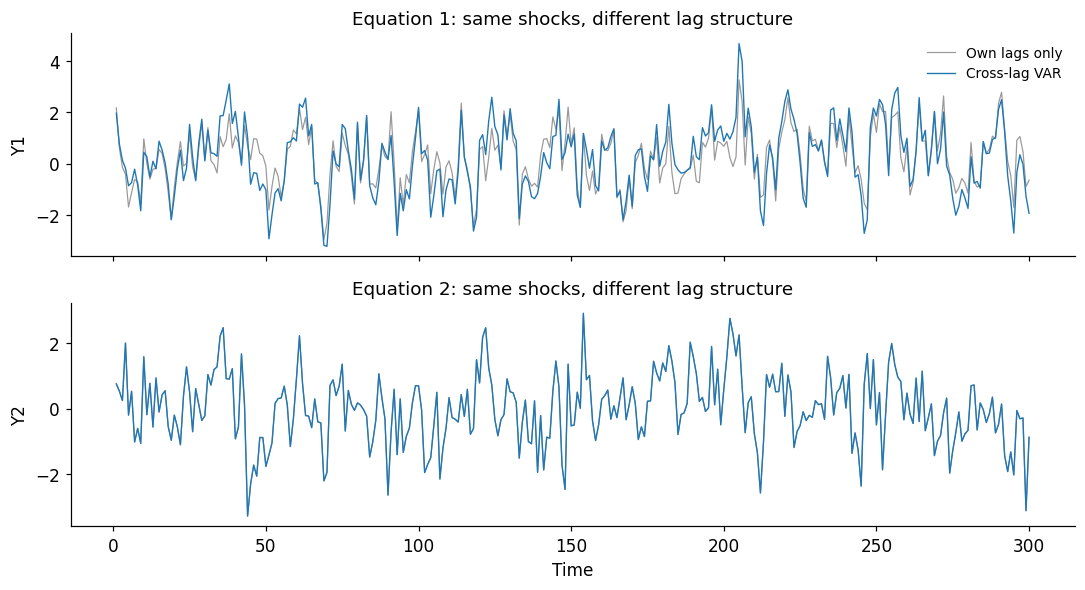

In [2]:
A_true = np.array([[.55, .35], [0., .40]])
Sigma_true = np.array([[1., .30], [.30, 1.]])
rng = np.random.default_rng(12012)
burn_in, sample_size, training_size, horizon = 1000, 800, 600, 24
shocks = rng.multivariate_normal(np.zeros(2), Sigma_true, size=burn_in + sample_size)
# These recursions illustrate the stated DGP; no coefficient clipping is used.
def simulated_history(matrix):
    values = np.empty_like(shocks)
    previous = np.zeros(2)
    for t, shock in enumerate(shocks):
        previous = matrix @ previous + shock
        values[t] = previous
    return values[burn_in:]

coupled_values = simulated_history(A_true)
diagonal_values = simulated_history(np.diag(np.diag(A_true)))
history = pd.DataFrame(coupled_values, columns=["Y1", "Y2"], index=np.arange(1, sample_size + 1))
train, reserved = history.iloc[:training_size], history.iloc[training_size:]
assert len(train) == 600 and len(reserved) == 200
Gamma_true = solve_discrete_lyapunov(A_true, Sigma_true)
np.testing.assert_allclose(Gamma_true, A_true @ Gamma_true @ A_true.T + Sigma_true)
print("Population companion eigenvalues:", np.linalg.eigvals(A_true))
display(pd.DataFrame(Gamma_true, index=history.columns, columns=history.columns).round(4))
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
for j, ax in enumerate(axes):
    ax.plot(train.index[:300], diagonal_values[:300, j], color="0.6", lw=.8, label="Own lags only")
    ax.plot(train.index[:300], coupled_values[:300, j], color="C0", lw=.9, label="Cross-lag VAR")
    ax.set(ylabel=f"Y{j+1}", title=f"Equation {j+1}: same shocks, different lag structure")
axes[0].legend(fontsize=9)
axes[-1].set_xlabel("Time")
fig.tight_layout(); plt.show()


The second histories coincide because its equation is unchanged. The first histories differ because the cross-lag transmits the second variable's past into the first. A visually similar movement could also arise from contemporaneously correlated innovations; a plot alone cannot identify the mechanism.

### Population and Sample Lag Relationships

The next figure compares $\operatorname{Corr}(Y_{i,t},Y_{j,t-h})$ for all four variable pairs, using only estimation observations. Population lag covariances come from $A_1^h\Gamma_0$. Sample correlations are calculated from the aligned pairs at each lag. They are descriptive, not simultaneous significance tests. Even when $a_{21}=0$, pairwise cross-correlations can reflect indirect dependence and shared innovations; they are not regression coefficients.

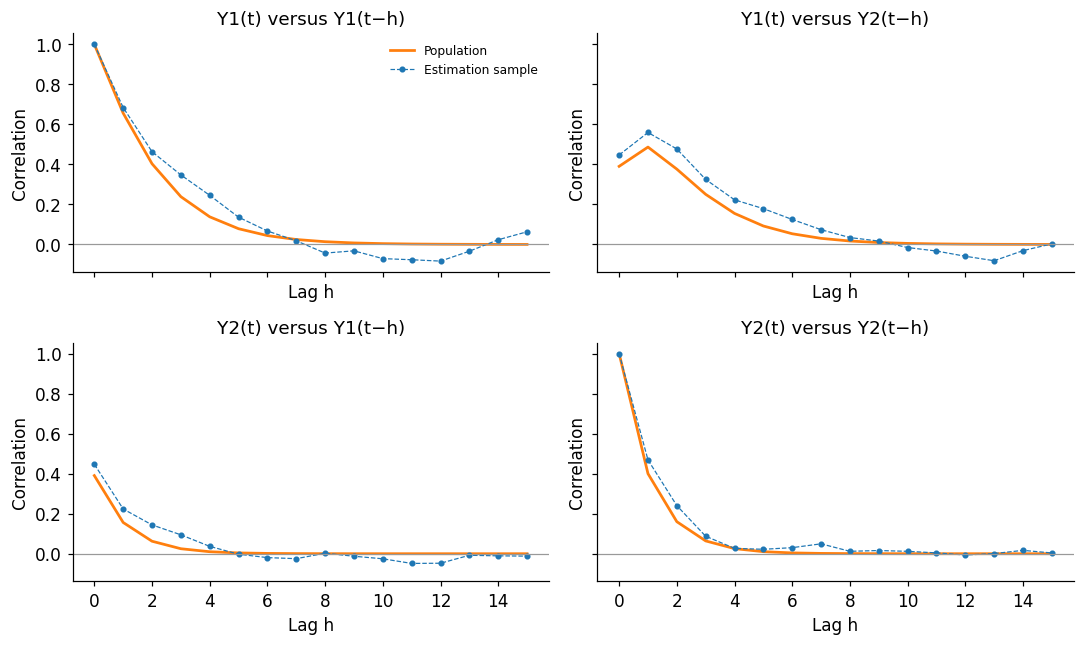

In [3]:
lags = np.arange(16)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for i in range(2):
    for j in range(2):
        population = [(np.linalg.matrix_power(A_true, int(h)) @ Gamma_true)[i,j]
                      / np.sqrt(Gamma_true[i,i] * Gamma_true[j,j]) for h in lags]
        empirical = [np.corrcoef(train.iloc[int(h):, i], train.iloc[:len(train)-int(h), j])[0,1]
                     for h in lags]
        ax = axes[i,j]
        ax.plot(lags, population, color="C1", label="Population")
        ax.plot(lags, empirical, "o--", ms=3, lw=.8, color="C0", label="Estimation sample")
        ax.axhline(0, color="0.6", lw=.8)
        ax.set(title=f"Y{i+1}(t) versus Y{j+1}(t−h)", xlabel="Lag h", ylabel="Correlation")
axes[0,0].legend(fontsize=8)
fig.tight_layout(); plt.show()


## 2. Estimation, Lag Selection and Diagnostics

### Estimation

With the same regressors in every equation, unrestricted equation-by-equation OLS estimates a VAR. Under IID Gaussian innovations it also maximizes the conditional Gaussian likelihood given the initial lagged observations. Correlated equation errors do not change this OLS equivalence when the regressors are identical across equations.

Write $Y=XB+U$ for the retained observations. Then
$$\widehat B=(X^\top X)^{-1}X^\top Y,\qquad
\widehat\Sigma_{u,ML}=\widehat U^\top\widehat U/N.$$
The inverse notation assumes full column rank; numerical least squares need not explicitly invert $X^\top X$. Estimated coefficient standard errors depend on the sampling assumptions. The package also reports a degrees-of-freedom-adjusted residual covariance, which differs from its likelihood covariance.

### Lag Selection

As in Notebook 03, compare maximized likelihood and parameter count on common observations:
$$AIC=-2\ell+2m,\qquad BIC=-2\ell+m\log N.$$
For $K$ variables, $p$ lags and an estimated constant, $m=K(1+Kp)+K(K+1)/2$, including the innovation covariance parameters. Flexibility grows quickly with both the system size and lag order.

I compare orders zero through five using training BIC, with AIC as a cross-check. Every candidate has the same 595 target observations; only the required presample lags vary. The grid is an explicit search choice, not a coefficient constraint. Statsmodels' VAR criteria use a per-observation convention that omits the common covariance-parameter penalty. The totals below retain the familiar convention from the earlier notebooks and give the same order ranking for fixed $K$.

In [4]:
max_lags = 5
candidate_fits, criterion_rows = {}, []
for order in range(max_lags + 1):
    candidate = VAR(train.iloc[max_lags-order:].reset_index(drop=True)).fit(order, trend="c")
    assert candidate.nobs == len(train) - max_lags
    candidate_fits[order] = candidate
    K, N = candidate.neqs, candidate.nobs
    parameter_count = K * (1 + K * order) + K * (K + 1) // 2
    criterion_rows.append({"Order": order, "n": N, "Parameters": parameter_count,
                          "Log-likelihood": candidate.llf,
                          "AIC": -2 * candidate.llf + 2 * parameter_count,
                          "BIC": -2 * candidate.llf + np.log(N) * parameter_count})
criteria = pd.DataFrame(criterion_rows).set_index("Order")
selected_order = int(criteria.BIC.idxmin())
fit = candidate_fits[selected_order]
# The established implementation's common-sample order search agrees.
assert selected_order == VAR(train.reset_index(drop=True)).select_order(max_lags, trend="c").selected_orders["bic"]
display(criteria.round(3))
print("Training BIC-selected order:", selected_order)
coefficient_table = pd.concat({"Estimate": fit.params, "Standard error": fit.stderr,
                               "p-value": fit.pvalues}, axis=1)
display(coefficient_table.round(4))
if selected_order == 1:
    comparison = pd.DataFrame({"Population": A_true.ravel(), "Estimate": fit.coefs[0].ravel()},
        index=["Y1 ← Y1 lag", "Y1 ← Y2 lag", "Y2 ← Y1 lag", "Y2 ← Y2 lag"])
    display(comparison.round(4))
    np.testing.assert_allclose(fit.coefs[0], fit.params.iloc[1:].to_numpy().T)
print("Estimated companion eigenvalue moduli:",
      np.abs(np.linalg.eigvals(comp_matrix(fit.coefs))) if selected_order else "No lag dynamics")
print("Estimated VAR stable:", fit.is_stable())


,n,Parameters,Log-likelihood,AIC,BIC
Order,,,,,
0,595,5,-1914.309,3838.619,3860.561
1,595,9,-1640.526,3299.051,3338.549
2,595,13,-1639.072,3304.143,3361.194
3,595,17,-1634.680,3303.360,3377.965
4,595,21,-1633.963,3309.926,3402.085
5,595,25,-1631.636,3313.271,3422.986


Training BIC-selected order: 1


Estimate         Standard error         p-value        
            Y1      Y2             Y1      Y2      Y1      Y2
const   0.0794 -0.0136         0.0404  0.0410  0.0497  0.7406
L1.Y1   0.5409  0.0124         0.0308  0.0313  0.0000  0.6909
L1.Y2   0.4174  0.4635         0.0400  0.0406  0.0000  0.0000

,Population,Estimate
Y1 ← Y1 lag,0.55,0.5409
Y1 ← Y2 lag,0.35,0.4174
Y2 ← Y1 lag,0.00,0.0124
Y2 ← Y2 lag,0.40,0.4635


Estimated companion eigenvalue moduli: [0.58400385 0.42046218]
Estimated VAR stable: True


The selected order and estimated coefficients describe this estimation sample. BIC need not recover the generating order in every history. Stability is checked after estimation, while coefficient p-values are conditional on the selected specification and do not account for selection uncertainty.

### Residual Diagnostics

Residuals estimate the innovations left unexplained by the fitted conditional mean. Check lagged relationships between all residual components, not only each component's own autocorrelation. The multivariate portmanteau test jointly screens residual autocovariance matrices through a specified lag. Non-rejection does not prove independence, constant conditional covariance or a correct density.

I report the adjusted lag-20 portmanteau check and a multivariate normality check. The normality check concerns the Gaussian likelihood assumption. The Gaussian simulation supplies a known reference, but its finite residual sample can still produce a rejection. Model adequacy remains separate from information-criterion ranking.

,Statistic,p-value
Check,,
"Residual portmanteau, lag 20",62.8989,0.8590
Residual multivariate normality,2.7746,0.5962


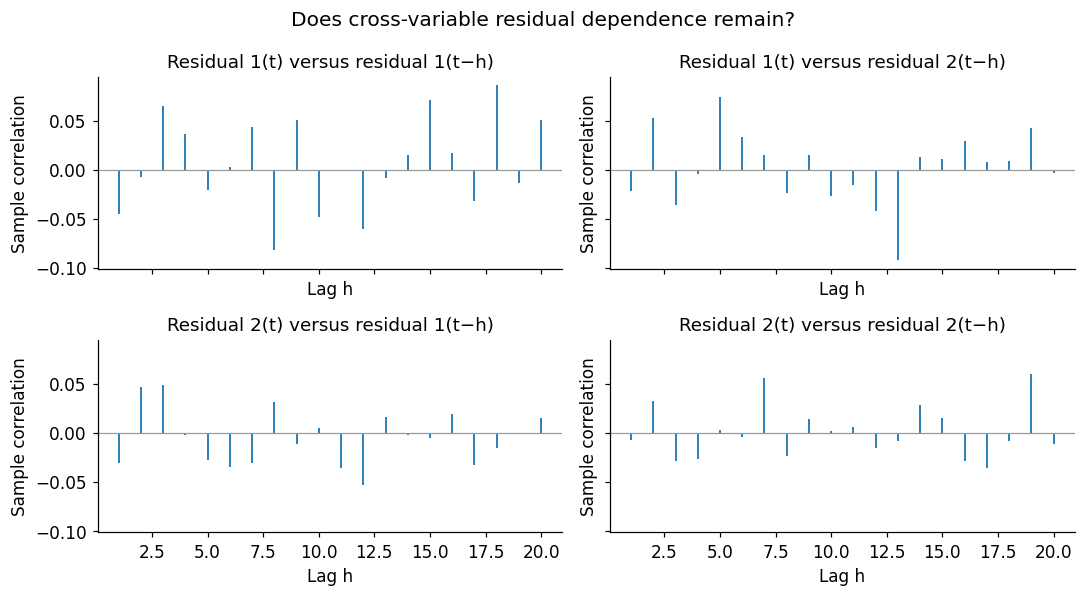

In [5]:
whiteness = fit.test_whiteness(nlags=20, adjusted=True)
normality = fit.test_normality()
display(pd.DataFrame([
    {"Check": "Residual portmanteau, lag 20", "Statistic": whiteness.test_statistic,
     "p-value": whiteness.pvalue},
    {"Check": "Residual multivariate normality", "Statistic": normality.test_statistic,
     "p-value": normality.pvalue},
]).set_index("Check").round(4))
residuals = np.asarray(fit.resid)
fig, axes = plt.subplots(2, 2, figsize=(10, 5.5), sharex=True, sharey=True)
for i in range(2):
    for j in range(2):
        values = [np.corrcoef(residuals[h:,i], residuals[:-h,j])[0,1] for h in range(1,21)]
        axes[i,j].vlines(np.arange(1,21), 0, values, color="C0", lw=1.2)
        axes[i,j].axhline(0, color="0.6", lw=.8)
        axes[i,j].set(title=f"Residual {i+1}(t) versus residual {j+1}(t−h)",
                      xlabel="Lag h", ylabel="Sample correlation")
fig.suptitle("Does cross-variable residual dependence remain?")
fig.tight_layout(); plt.show()


## 3. Granger Predictability

A predictive relationship asks whether one variable's lagged observations improve another equation after controlling for the remaining system history.

**Definition: Granger non-causality within a VAR.** Variable $Y_2$ does not Granger-predict $Y_1$ when its coefficients in the first equation are jointly zero:
$$H_0:(A_1)_{12}=\cdots=(A_p)_{12}=0.$$
The alternative is that at least one is nonzero. Test all relevant lags together, rather than selecting one coefficient's p-value.

This is conditional predictive information within the specified variables and lag structure, not an intervention-based causal claim. Omitted variables, temporal aggregation and specification errors can change the interpretation. Contemporaneous correlation alone does not establish the lagged relationship.

In this DGP, $Y_2$ Granger-predicts $Y_1$, while $Y_1$ does not Granger-predict $Y_2$. I test both directions using the selected training model. A finite sample need not reproduce both population conclusions.

In [6]:
if selected_order:
    granger_rows = []
    for causing, caused in [("Y2", "Y1"), ("Y1", "Y2")]:
        result = fit.test_causality(caused, [causing], kind="f")
        granger_rows.append({"Direction": f"{causing} → {caused}",
                             "F statistic": result.test_statistic, "p-value": result.pvalue})
    display(pd.DataFrame(granger_rows).set_index("Direction").round(5))
else:
    print("The selected VAR(0) has no lag coefficients to test for Granger predictability.")


,F statistic,p-value
Direction,,
Y2 → Y1,109.01132,0.00000
Y1 → Y2,0.15811,0.69098


## 4. Innovation Propagation and Impulse Responses

The moving-average matrices $\Phi_h$ describe how an innovation vector enters later observations. In VAR(1), $\Phi_h=A_1^h$. A one-unit change in innovation component $j$, holding the other components at zero, changes the conditional path by $\Phi_h\mathbf e_j$.

These are algebraic reduced-form responses. When innovations are contemporaneously correlated, changing one component independently is not automatically an identified economic shock. Orthogonal responses require additional identifying assumptions.

For illustration, I compare fitted reduced-form responses with the known population responses over 20 lags. The matrices' columns identify the perturbed component and their rows identify the response variable. There are no coefficient-confidence bands here; agreement concerns one estimated history.

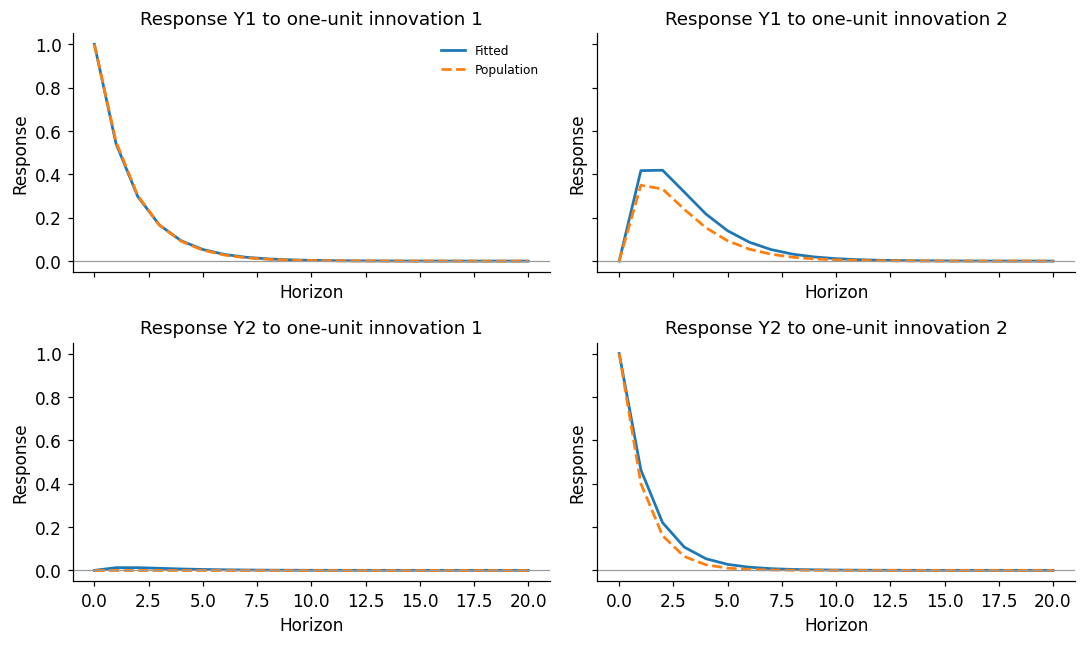

In [7]:
response_horizon = 20
estimated_responses = fit.ma_rep(maxn=response_horizon)
true_responses = np.array([np.linalg.matrix_power(A_true, h) for h in range(response_horizon + 1)])
np.testing.assert_allclose(estimated_responses[0], np.eye(2))
for h in range(1, response_horizon + 1):
    recursive = sum((fit.coefs[j-1] @ estimated_responses[h-j]
                     for j in range(1, min(selected_order,h)+1)), start=np.zeros((2,2)))
    np.testing.assert_allclose(estimated_responses[h], recursive)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True)
for i in range(2):
    for j in range(2):
        axes[i,j].plot(np.arange(response_horizon+1), estimated_responses[:,i,j], label="Fitted")
        axes[i,j].plot(np.arange(response_horizon+1), true_responses[:,i,j], "--", color="C1", label="Population")
        axes[i,j].axhline(0, color="0.6", lw=.8)
        axes[i,j].set(title=f"Response Y{i+1} to one-unit innovation {j+1}", xlabel="Horizon", ylabel="Response")
axes[0,0].legend(fontsize=8)
fig.tight_layout(); plt.show()


### Orthogonalization and Variable Ordering

A Cholesky factorization $\widehat\Sigma_u=PP^\top$ writes innovations as $\mathbf u_t=P\boldsymbol\eta_t$ with unit-covariance components. The corresponding responses are $\widehat\Phi_hP$. This recursive identification assigns contemporaneous effects according to variable ordering. It is an assumption, not a consequence of estimating a VAR.

I fit the identical selected specification with the columns reversed, using the same observations. The next figure shows how the response to the orthogonal shock associated with $Y_1$ changes with this ordering. Each shock has unit variance in its orthogonalized representation; its mapping into observed innovations changes. Neither ordering is selected because it produces a more attractive result.

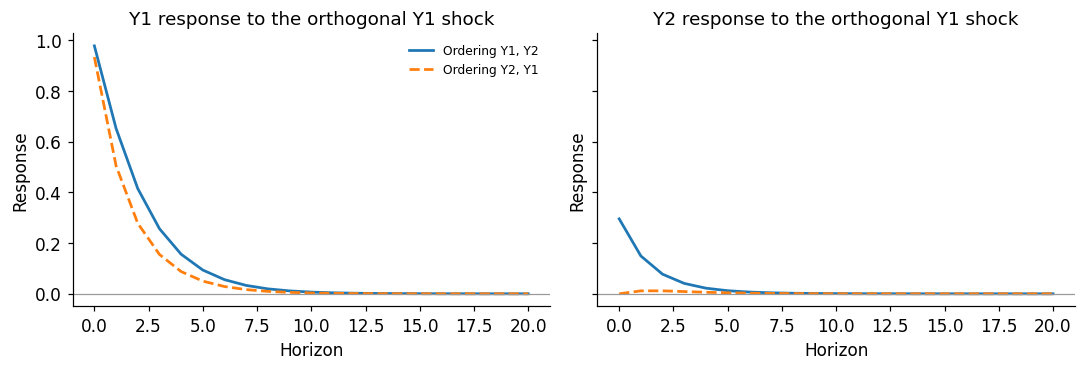

In [8]:
reordered_fit = VAR(train.iloc[max_lags-selected_order:][["Y2", "Y1"]].reset_index(drop=True)).fit(selected_order, trend="c")
np.testing.assert_allclose(reordered_fit.coefs[:, ::-1, ::-1], fit.coefs, atol=1e-10)
P = np.linalg.cholesky(fit.sigma_u)
responses_first = estimated_responses @ P
responses_reversed = reordered_fit.ma_rep(maxn=response_horizon) @ np.linalg.cholesky(reordered_fit.sigma_u)
np.testing.assert_allclose(P @ P.T, fit.sigma_u)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True, sharey=True)
for i, ax in enumerate(axes):
    ax.plot(np.arange(response_horizon+1), responses_first[:,i,0], label="Ordering Y1, Y2")
    ax.plot(np.arange(response_horizon+1), responses_reversed[:,1-i,1], "--", label="Ordering Y2, Y1")
    ax.axhline(0, color="0.6", lw=.8)
    ax.set(title=f"Y{i+1} response to the orthogonal Y1 shock", xlabel="Horizon", ylabel="Response")
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()


## 5. Forecasting and Evaluation

### Conditional Mean and Forecast Uncertainty

With IID mean-zero innovations, forecasts iterate the conditional-mean equations:
$$\widehat{\mathbf y}_{n+h|n}=\widehat{\mathbf c}
+\sum_{j=1}^p\widehat A_j\widehat{\mathbf y}_{n+h-j|n},$$
using observed values when $h-j\le0$. For known parameters, the forecast-error covariance is
$$\Omega_h=\sum_{j=0}^{h-1}\Phi_j\Sigma_u\Phi_j^\top.$$
At one step it equals innovation covariance. Longer-horizon uncertainty includes shock propagation and cross-variable dependence. Plug-in forecasts substitute estimated parameters and omit their estimation uncertainty.

I forecast the first 24 reserved observations from the end of the training period, without refitting. The Gaussian 95% bands are marginal, pointwise prediction intervals, not a joint 95% region for both variables or an interval for the whole path. Their validity relies on the density assumption as well as estimated dynamics.

### Benchmarks

Compare the fitted VAR with separate own-lag AR models of the same selected order. Each benchmark uses identical estimation targets and its own variable's lags, but excludes the other variable's lags. A known-parameter population forecast illustrates estimation error; it would not be available in a market application. Report ME, RMSE and MAE for each variable, preserving Notebook 08's error convention.

ME    RMSE     MAE
Model                Variable                        
Fitted VAR           Y1       -0.7142  1.4733  1.2216
                     Y2        0.2141  1.1779  0.9364
Separate own-lag AR  Y1       -0.7057  1.4849  1.2285
                     Y2        0.2100  1.1758  0.9341
Known population VAR Y1       -0.5820  1.4155  1.1679
                     Y2        0.1817  1.1688  0.9292

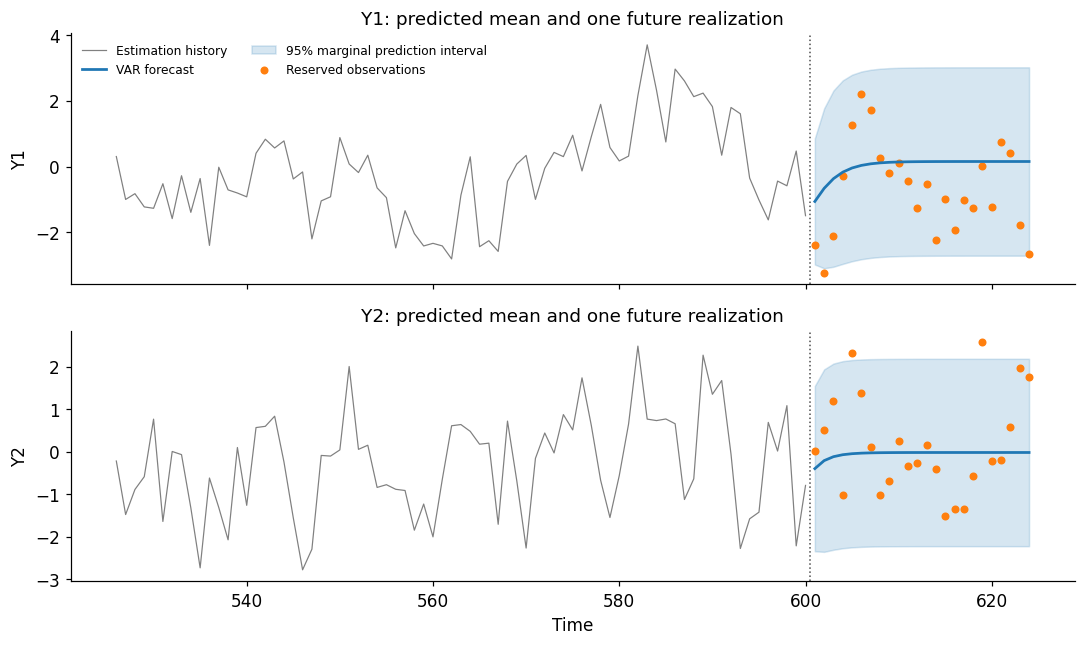

In [9]:
forecast_history = train.to_numpy()[-selected_order:] if selected_order else np.empty((0,2))
if selected_order:
    predicted, lower, upper = fit.forecast_interval(forecast_history, horizon, alpha=.05)
else:
    predicted = np.tile(fit.intercept, (horizon,1))
    sd = np.sqrt(np.diag(fit.sigma_u))
    lower, upper = predicted-stats.norm.ppf(.975)*sd, predicted+stats.norm.ppf(.975)*sd
explicit = []
forecast_values = list(train.to_numpy())
for h in range(horizon):
    current = np.asarray(fit.intercept).copy()
    for j, matrix in enumerate(fit.coefs,1):
        current += matrix @ forecast_values[-j]
    explicit.append(current); forecast_values.append(current)
np.testing.assert_allclose(predicted, explicit)
forecast_covariance = fit.forecast_cov(horizon)
calculated_covariance = np.cumsum(np.array([phi @ np.asarray(fit.sigma_u) @ phi.T
                                          for phi in fit.ma_rep(maxn=horizon-1)]), axis=0)
np.testing.assert_allclose(forecast_covariance, calculated_covariance)

own_predictions = np.empty_like(predicted)
targets = train.to_numpy()[-fit.nobs:]
X_full = fit.endog_lagged
for j in range(2):
    columns = [0] + [1 + lag*2 + j for lag in range(selected_order)]
    coefficients = np.linalg.lstsq(X_full[:,columns], targets[:,j], rcond=None)[0]
    own_history = list(train.iloc[:,j].to_numpy())
    for h in range(horizon):
        value = coefficients[0] + sum(coefficients[lag] * own_history[-lag]
                                      for lag in range(1,selected_order+1))
        own_predictions[h,j] = value; own_history.append(value)
population_predictions = np.array([np.linalg.matrix_power(A_true, h) @ train.iloc[-1].to_numpy()
                                   for h in range(1,horizon+1)])
actual = reserved.iloc[:horizon]
forecast_rows = []
for name, prediction in [("Fitted VAR",predicted),("Separate own-lag AR",own_predictions),
                         ("Known population VAR",population_predictions)]:
    for j in range(2):
        errors = actual.iloc[:,j].to_numpy() - prediction[:,j]
        forecast_rows.append({"Model":name,"Variable":history.columns[j],
                              "ME":errors.mean(),"RMSE":np.sqrt(np.mean(errors**2)),"MAE":np.mean(np.abs(errors))})
display(pd.DataFrame(forecast_rows).set_index(["Model","Variable"]).round(4))
fig, axes = plt.subplots(2,1,figsize=(10,6),sharex=True)
for j,ax in enumerate(axes):
    ax.plot(train.index[-75:],train.iloc[-75:,j],color="0.5",lw=.8,label="Estimation history")
    ax.plot(actual.index,predicted[:,j],color="C0",label="VAR forecast")
    ax.fill_between(actual.index,lower[:,j],upper[:,j],color="C0",alpha=.18,label="95% marginal prediction interval")
    ax.scatter(actual.index,actual.iloc[:,j],color="C1",s=18,label="Reserved observations")
    ax.axvline(training_size+.5,color="0.3",ls=":",lw=1)
    ax.set(ylabel=history.columns[j],title=f"{history.columns[j]}: predicted mean and one future realization")
axes[0].legend(fontsize=8,ncol=2);axes[-1].set_xlabel("Time")
fig.tight_layout();plt.show()


A multivariate conditional mean can use information excluded by separate own-history models. That potential does not guarantee a smaller realized error: additional estimated coefficients introduce uncertainty, and one 24-observation continuation is short. Even the known-parameter conditional expectation need not be the best realized forecast in every sample.

Cross-variable lag coefficients, contemporaneous covariance, Granger predictability and identified shock responses answer different questions. A stable fitted VAR is not automatically an adequate model, and non-rejection of residual tests does not prove its assumptions.

The stable examples here have finite population covariance and no stochastic trend. When levels contain unit roots, differencing can remove that trend but may discard a shared long-run relationship. Notebook 13 develops cointegration and error correction to retain that information.